# 19장 · 에너지 등분배 — 예제 풀이

**열및통계물리2 · 교재 19장 에너지 등분배 (Blundell & Blundell, *Concepts in Thermal Physics* 2판)**

이 노트북은 교재 19장의 예제를 Python으로 확인한다. 위에서부터 순서대로 실행하면 된다(Colab: 런타임 → 모두 실행).
각 예제는 **문제 요약 → 풀이 아이디어 → 코드 → 결과 → 해석** 순서이다. 단위는 SI, 그래프 라벨은 영어로 쓴다.
쪽수는 교재 한국어판 기준이다.

In [1]:
# ── 0. 준비: 라이브러리와 물리 상수 ──────────────────────────────
import numpy as np
import scipy.constants as sc
from scipy import integrate, optimize, special
import matplotlib.pyplot as plt

# 물리 상수 (SI 단위). 출처: scipy.constants = CODATA 2018 권장값
kB   = sc.k            # 볼츠만 상수 [J/K]
h    = sc.h            # 플랑크 상수 [J s]
hbar = sc.hbar         # [J s]
c    = sc.c            # 광속 [m/s]
e    = sc.e            # 기본 전하 [C]  (1 eV = e J)
NA   = sc.N_A          # 아보가드로 수 [1/mol]
R    = sc.R            # 기체 상수 [J/(mol K)]
me   = sc.m_e          # 전자 질량 [kg]
mp   = sc.m_p          # 양성자 질량 [kg]
amu  = sc.atomic_mass  # 원자 질량 단위 u [kg]
muB  = sc.physical_constants['Bohr magneton'][0]   # 보어 자기량 [J/T]
mu0  = sc.mu_0         # 진공 투자율 [N/A^2]
sigma_SB = sc.Stefan_Boltzmann                      # 스테판-볼츠만 상수 [W m^-2 K^-4]

plt.rcParams.update({'figure.figsize': (6.4, 4.0), 'axes.grid': True, 'grid.alpha': 0.3})

def compare(label, value, book, unit='', rtol=0.05):
    """계산값과 교재 답을 나란히 출력한다. rtol: 허용 상대오차 (교재 답은 보통 유효숫자 2자리)."""
    rel = abs(value - book) / abs(book)
    flag = 'OK' if rel <= rtol else 'CHECK'
    print(f'{label}: computed = {value:.4g} {unit} | textbook = {book:.4g} {unit} | rel. diff = {rel:.2%} [{flag}]')
    return rel

print('Setup complete. numpy', np.__version__)

Setup complete. numpy 2.5.3


## 예제 19.1 — 제곱항 $n$개의 평균 에너지 (교재 273–274쪽)

**문제 요약.** 에너지가 서로 독립인 제곱항 $n$개의 합 $E=\sum_{i=1}^n\alpha_i x_i^2$이고, 계가 온도 $T$인 열원과 접해 있을 때 평균 에너지 $\langle E\rangle$를 구한다.

**풀이 아이디어.** 볼츠만 확률 $P\propto e^{-\beta E}$가 각 $x_i$에 대해 곱으로 나뉘므로 항마다 따로 적분한다(교재 식 19.9–19.11).
여기서는 (1) 한 항의 적분 $\langle\alpha x^2\rangle=\int\alpha x^2e^{-\beta\alpha x^2}dx/\int e^{-\beta\alpha x^2}dx$를 수치적분하고,
(2) 각 $x_i$를 분산 $k_BT/2\alpha_i$인 정규분포에서 뽑아 몬테카를로로 $\langle E\rangle$를 구해, 둘 다 $\tfrac n2k_BT$와 비교한다.

n = 1:  integral <E>/kT = 0.500000,  Monte Carlo <E>/kT = 0.4988,  n/2 = 0.5
n = 2:  integral <E>/kT = 1.000000,  Monte Carlo <E>/kT = 0.9976,  n/2 = 1.0
n = 3:  integral <E>/kT = 1.500000,  Monte Carlo <E>/kT = 1.4962,  n/2 = 1.5
n = 4:  integral <E>/kT = 2.000000,  Monte Carlo <E>/kT = 1.9978,  n/2 = 2.0
n = 5:  integral <E>/kT = 2.500000,  Monte Carlo <E>/kT = 2.5018,  n/2 = 2.5
n = 6:  integral <E>/kT = 3.000000,  Monte Carlo <E>/kT = 3.0043,  n/2 = 3.0
n = 7:  integral <E>/kT = 3.500000,  Monte Carlo <E>/kT = 3.5026,  n/2 = 3.5


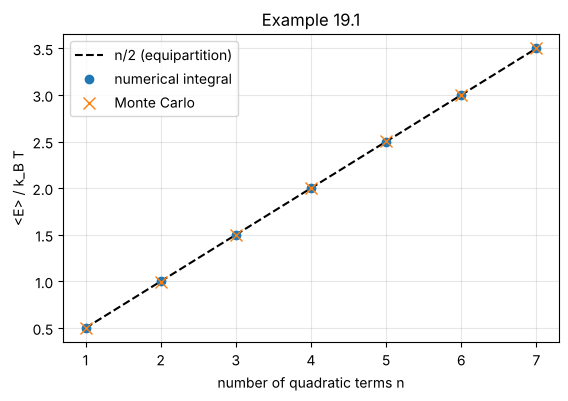

In [2]:
T = 300.0                          # 온도 [K] (임의로 고른 값; 결과는 k_BT 단위로 본다)
beta = 1 / (kB * T)
rng = np.random.default_rng(1)

def mean_quadratic(alpha):
    """한 제곱항의 평균 에너지 <alpha x^2> [J] — 수치적분 (교재 식 19.6)"""
    w = np.sqrt(1 / (beta * alpha))                     # 분포 폭 정도의 길이
    num = integrate.quad(lambda x: alpha * x**2 * np.exp(-beta * alpha * x**2), -12 * w, 12 * w, points=[0.0], epsabs=0, epsrel=1e-12)[0]
    den = integrate.quad(lambda x: np.exp(-beta * alpha * x**2), -12 * w, 12 * w, points=[0.0], epsabs=0, epsrel=1e-12)[0]
    return num / den

ns = np.arange(1, 8)
E_int, E_mc = [], []
for n in ns:
    alphas = 10.0 ** rng.uniform(-2, 2, size=n)        # 서로 다른 계수 alpha_i [J/m^2] (임의)
    E_int.append(sum(mean_quadratic(a) for a in alphas))
    x = rng.normal(0, np.sqrt(kB * T / (2 * alphas)), size=(200_000, n))   # 볼츠만 분포 = 정규분포
    E_mc.append(np.mean(np.sum(alphas * x**2, axis=1)))

E_int, E_mc = np.array(E_int), np.array(E_mc)
for n, a, b in zip(ns, E_int / (kB * T), E_mc / (kB * T)):
    print(f'n = {n}:  integral <E>/kT = {a:.6f},  Monte Carlo <E>/kT = {b:.4f},  n/2 = {n/2}')

plt.plot(ns, ns / 2, 'k--', label='n/2 (equipartition)')
plt.plot(ns, E_int / (kB * T), 'o', label='numerical integral')
plt.plot(ns, E_mc / (kB * T), 'x', ms=9, label='Monte Carlo')
plt.xlabel('number of quadratic terms n'); plt.ylabel('<E> / k_B T'); plt.legend(); plt.title('Example 19.1'); plt.show()

**해석.** 계수 $\alpha_i$를 $10^{-2}$–$10^{2}$로 마구 골랐는데도 평균 에너지는 정확히 $\tfrac n2k_BT$이다(교재 식 19.12).
제곱항 하나는 계수와 무관하게 $\tfrac12k_BT$를 갖는다는 것이 등분배 정리의 내용이다.

## 예제 19.2 — 용수철에 매달린 질량과 상온의 $k_BT$ (교재 275쪽)

**문제 요약.** 용수철에 매달린 질량의 에너지 $\tfrac12mv^2+\tfrac12kx^2$는 제곱항 2개이므로 평균 에너지는 $k_BT$이다.
교재는 상온에서 $k_BT\approx4\times10^{-21}$ J $\approx0.025$ eV이고, 이 에너지로는 10 kg 질량을 눈에 띄게 흔들 수 없다고 말한다.

**풀이 아이디어.** $k_BT$를 J과 eV로 계산해 교재 값과 비교한다. 진폭은 $\tfrac12k\langle x^2\rangle=\tfrac12k_BT$에서 $x_{\rm rms}=\sqrt{k_BT/k}$이다.
교재에는 용수철 상수가 없으므로, **가정**으로 주기 1 s($k=m(2\pi)^2$)인 10 kg 질량을 쓴다.

In [3]:
for T in (293.0, 300.0):
    kT = kB * T
    print(f'T = {T:.0f} K:  k_BT = {kT:.3e} J = {kT / e:.4f} eV')
compare('k_BT at 300 K [J]', kB * 300, 4e-21, 'J', rtol=0.05)
compare('k_BT at 300 K [eV]', kB * 300 / e, 0.025, 'eV', rtol=0.05)

# 10 kg 질량, 주기 1 s (가정) → 열적 진폭
m = 10.0                                # [kg]
k_spring = m * (2 * np.pi / 1.0) ** 2   # [N/m]
x_rms = np.sqrt(kB * 300 / k_spring)    # [m]
print(f'spring constant = {k_spring:.1f} N/m,  thermal x_rms = {x_rms:.2e} m')

T = 293 K:  k_BT = 4.045e-21 J = 0.0252 eV
T = 300 K:  k_BT = 4.142e-21 J = 0.0259 eV
k_BT at 300 K [J]: computed = 4.142e-21 J | textbook = 4e-21 J | rel. diff = 3.55% [OK]
k_BT at 300 K [eV]: computed = 0.02585 eV | textbook = 0.025 eV | rel. diff = 3.41% [OK]
spring constant = 394.8 N/m,  thermal x_rms = 3.24e-12 m


**해석.** 상온의 $k_BT\approx4.1\times10^{-21}$ J $\approx0.026$ eV로 교재 값과 맞는다.
주기 1 s인 10 kg 진동자의 열적 진폭은 $\sim3\times10^{-12}$ m로 원자 크기보다 작아 눈으로 볼 수 없다. 반면 같은 $k_BT$가 원자 결합 같은 작은 계에서는 의미 있는 진동을 만든다.

## 예제 19.3 — 브라운 운동 (교재 280–281쪽)

**문제 요약.** 물속 꽃가루 같은 작은 입자는 불규칙하게 움직인다. 교재는 등분배 $\tfrac12m\langle v^2\rangle=\tfrac32k_BT$에서 질량이 작을수록 $\langle v^2\rangle$가 크다는 점을 지적한다(수치 답 없음).

**풀이 아이디어.** $v_{\rm rms}=\sqrt{3k_BT/m}$을 입자 크기에 따라 계산한다. **가정:** 밀도 $1000$ kg/m³인 구, 반지름 0.1–10 μm, $T=293$ K.

radius   0.1 um: mass = 4.19e-18 kg, v_rms = 5.383e-02 m/s
radius   1.0 um: mass = 4.19e-15 kg, v_rms = 1.702e-03 m/s
radius  10.0 um: mass = 4.19e-12 kg, v_rms = 5.383e-05 m/s


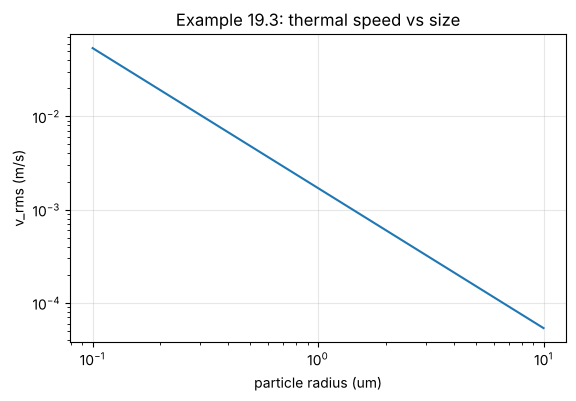

log-log slope = -1.500 (expected -3/2, since m ~ r^3)


In [4]:
T = 293.0
rho = 1000.0                                  # [kg/m^3] (가정)
r = np.logspace(-7, -5, 50)                   # 반지름 [m]
m = 4 / 3 * np.pi * r**3 * rho                # 질량 [kg]
v_rms = np.sqrt(3 * kB * T / m)               # [m/s]  (교재: (1/2) m <v^2> = (3/2) k_B T)

for ri in (1e-7, 1e-6, 1e-5):
    mi = 4 / 3 * np.pi * ri**3 * rho
    print(f'radius {ri*1e6:5.1f} um: mass = {mi:.2e} kg, v_rms = {np.sqrt(3*kB*T/mi):.3e} m/s')

plt.loglog(r * 1e6, v_rms)
plt.xlabel('particle radius (um)'); plt.ylabel('v_rms (m/s)'); plt.title('Example 19.3: thermal speed vs size'); plt.show()
slope = np.polyfit(np.log(r), np.log(v_rms), 1)[0]
print(f'log-log slope = {slope:.3f} (expected -3/2, since m ~ r^3)')

**해석.** 열운동 속도는 $v_{\rm rms}\propto m^{-1/2}\propto r^{-3/2}$이라 작은 입자일수록 빠르게 흔들린다.
1 μm 입자의 $v_{\rm rms}$는 mm/s 수준으로, 현미경에서 보이는 불규칙 운동이 등분배의 결과임을 보여 준다. 실제 관찰되는 변위는 유체의 점성 때문에 훨씬 느리게 퍼진다(교재는 33장에서 자세히 다룬다).